In [ ]:
# ### الخطوة 1: استيراد المكتبات
# نقوم هنا باستيراد كافة مكتبات بايثون المطلوبة لمعالجة البيانات، بناء الـ Pipeline، تدريب نماذج التصنيف، وتقييم الأداء.


In [10]:
# المكتبات الأساسية ومعالجة البيانات
import pandas as pd
import numpy as np

# مكتبات الرسم والتصور البصري
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_theme(style="whitegrid")

# أدوات تعلم الآلة وتقسيم البيانات
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix, ConfusionMatrixDisplay, roc_auc_score
)

# أدوات بناء الـ Pipeline والمعالجة المسبقة
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# نماذج التصنيف للمقارنة
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier

# أداة حفظ النماذج
import joblib

print("تم استيراد المكتبات بنجاح!")


تم استيراد المكتبات بنجاح!


In [ ]:
# ### الخطوة 2: تحميل البيانات واستكشافها (EDA)
# في هذه الخطوة، نقوم بقراءة البيانات، فحص أبعادها، معرفة أنواع الأعمدة (رقمية وفئوية)، والكشف عن أي قيم مفقودة لضمان فهمها قبل المعالجة[span_0](start_span)[span_0](end_span).


In [11]:
# قراءة بيانات المشروع (تأكد من رفع ملف الـ CSV الخاص بك أو استبداله بالمسار الصحيح)
# سنفترض هنا أننا نعمل على بيانات تصنيف (مثلاً بيانات سكتة دماغية أو عملاء)
df = pd.read_csv('healthcare-dataset-stroke-data.csv')

# عرض أول 5 صفوف
print("--- أول 5 صفوف من البيانات ---")
display(df.head())

# أبعاد البيانات
print(f"\nأبعاد البيانات: {df.shape[0]} صف و {df.shape[1]} أعمدة\n")

# فحص القيم المفقودة
print("--- القيم المفقودة لكل عمود ---")
print(df.isnull().sum())


--- أول 5 صفوف من البيانات ---


,id,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,9046,Male,67.0,0,1,Yes,Private,Urban,228.69,36.6,formerly smoked,1
1,51676,Female,61.0,0,0,Yes,Self-employed,Rural,202.21,NaN,never smoked,1
2,31112,Male,80.0,0,1,Yes,Private,Rural,105.92,32.5,never smoked,1
3,60182,Female,49.0,0,0,Yes,Private,Urban,171.23,34.4,smokes,1
4,1665,Female,79.0,1,0,Yes,Self-employed,Rural,174.12,24.0,never smoked,1



أبعاد البيانات: 5110 صف و 12 أعمدة

--- القيم المفقودة لكل عمود ---
id                     0
gender                 0
age                    0
hypertension           0
heart_disease          0
ever_married           0
work_type              0
Residence_type         0
avg_glucose_level      0
bmi                  201
smoking_status         0
stroke                 0
dtype: int64


In [ ]:
# ### الخطوة 2.5: الاستكشاف البصري ورسم المخططات (EDA & Visualization)
# وفقاً لأساسيات تحليل البيانات، يساعدنا الفحص البصري قبل المعالجة على فهم توزيع القيم، الكشف عن مدى توازن الفئات، ومعرفة سلوك المتغيرات الفئوية والرقمية[span_1](start_span)[span_1](end_span). سنقوم هنا برسم:
# 1. مخطط يوضح توزيع المتغير المستهدف (`Target`) لمعرفة حالة التوازن أو الاختلاف.
# 2. مخطط شريطي يوضح توزيع الفئات لأحد الأعمدة الفئوية (مثل حالة التدخين أو الجنس) استناداً إلى طرق الفحص السريع الموصعة في المحاضرات[span_2](start_span)[span_2](end_span).


/tmp/ipykernel_5862/2130131071.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.countplot(x=target_column, data=df, palette='Set2')


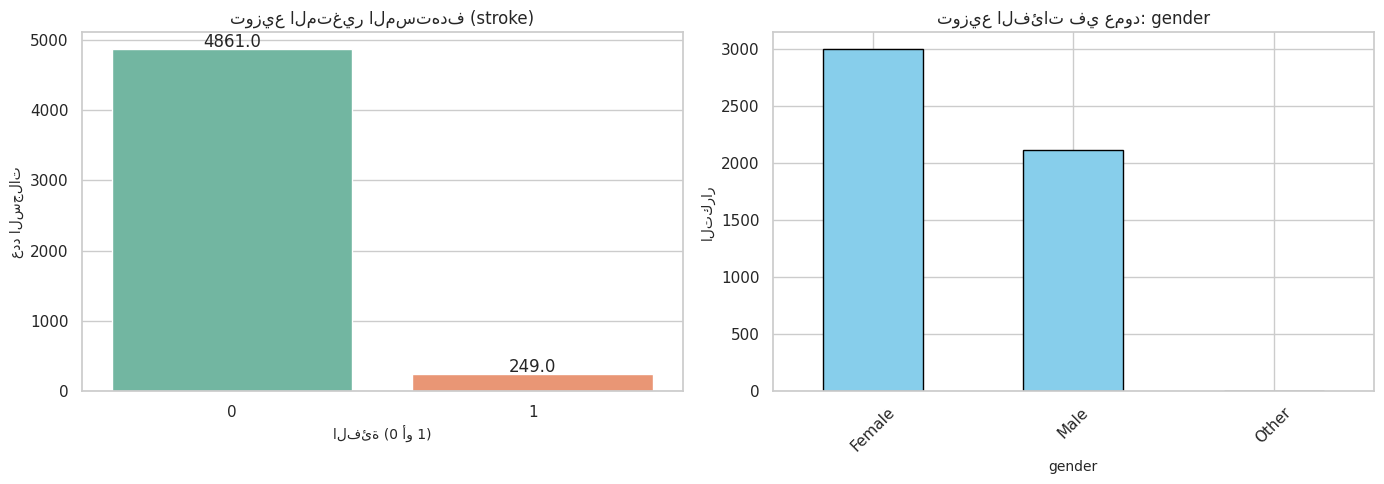

In [14]:
# تعريف المتغيرات المطلوبة للرسم
target_column = 'stroke'
categorical_features = df.select_dtypes(include=['object', 'category']).columns.tolist()

# ضبط مساحة الرسم
plt.figure(figsize=(14, 5))

# 1. مخطط توزيع المتغير المستهدف (Target Distribution)
plt.subplot(1, 2, 1)
ax = sns.countplot(x=target_column, data=df, palette='Set2')
plt.title(f'توزيع المتغير المستهدف ({target_column})', fontsize=12)
plt.xlabel('الفئة (0 أو 1)', fontsize=10)
plt.ylabel('عدد السجلات', fontsize=10)

# إضافة الأعداد فوق الأعمدة لتوضيح التوزيع بدقة
for p in ax.patches:
    ax.annotate(f'{p.get_height()}', (p.get_x() + p.get_width() / 2., p.get_height()),
                ha='center', va='center', xytext=(0, 5), textcoords='offset points')

# 2. مخطط توزيع الأعمدة الفئوية
if len(categorical_features) > 0:
    sample_cat_col = categorical_features[0]
    plt.subplot(1, 2, 2)
    df[sample_cat_col].value_counts().plot(kind='bar', color='skyblue', edgecolor='black')
    plt.title(f'توزيع الفئات في عمود: {sample_cat_col}', fontsize=12)
    plt.xlabel(sample_cat_col, fontsize=10)
    plt.ylabel('التكرار', fontsize=10)
    plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

In [ ]:
### الخطوة الثالثة: تقسيم البيانات أولاً (Train/Test Split) ومنع تسرب البيانات (Data Leakage)
#  (بنسبة 80% تدريب و 20% اختبار) قبل تنفيذ أي معالجة أو تعبئة للقيم المفقودة[span_2](start_span)[span_2](end_span)[span_3](start_span)[span_3](end_span). هذا يضمن عدم تسرب أي معلومات من بيانات الاختبار إلى نموذج التدريب، مما يعطينا تقييماً حقيقياً ودقيقاً لأداء النموذج[span_4](start_span)[span_4](end_span)[span_5](start_span)[span_5](end_span).


In [15]:
# تحديد العمود المستهدف (Target) والميزات (Features)
# تأكد أن 'stroke' هو اسم عمود الهدف في ملفك، أو قم بتغييره حسب الحاجة
target_column = 'stroke'

X = df.drop(columns=['id', target_column]) # إزالة الـ ID لأنه لا يفيد في التنبؤ
y = df[target_column]

# تقسيم البيانات إلى تدريب واختبار مع استخدام stratify للحفاظ على نسبة التوازن بين الفئات
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(f"حجم بيانات التدريب (Train): {X_train.shape}")
print(f"حجم بيانات الاختبار (Test): {X_test.shape}")


حجم بيانات التدريب (Train): (4088, 10)
حجم بيانات الاختبار (Test): (1022, 10)


In [16]:
# استبدال الكلمات "Unknown" في عمود حالة التدخين بقيم مفقودة حقيقية (NaN)
if 'smoking_status' in df.columns:
    df['smoking_status'] = df['smoking_status'].replace('Unknown', np.nan)
    print("تم تحويل قيم 'Unknown' إلى NaN ليتعامل معها الـ SimpleImputer تلقائياً داخل الـ Pipeline!")


تم تحويل قيم 'Unknown' إلى NaN ليتعامل معها الـ SimpleImputer تلقائياً داخل الـ Pipeline!


In [ ]:
# ### الخطوة الرابعة: بناء نظام الـ Pipeline والمعالجة المسبقة (Preprocessing & Pipeline)
# استناداً إلى ما تم شرحه في المحاضرات، سنقوم بتصميم نظام موحد يجمع خطوات معالجة البيانات في مكان واحد (`Pipeline` و `ColumnTransformer`) لضمان[span_2](start_span)[span_2](end_span)[span_3](start_span)[span_3](end_span):
# 1. **الأعمدة الرقمية:** تعبئة القيم المفقودة بالوسيط (`SimpleImputer`) وتوحيد المقاييس (`StandardScaler`)[span_4](start_span)[span_4](end_span)[span_5](start_span)[span_5](end_span).
# 2. **الأعمدة الفئوية:** تعبئة القيم المفقودة بالأكثر تكراراً وتحويل النصوص إلى أرقام عبر (`OneHotEncoder`) مع استخدام `handle_unknown='ignore'` للتعامل مع أي فئات جديدة قد تظهر في بيانات الاختبار[span_6](start_span)[span_6](end_span)[span_7](start_span)[span_7](end_span).
# 3. **منع تسرب البيانات (Data Leakage):** لأن الـ Pipeline سيتعلم الإحصائيات (مثل الوسيط والمتوسط) **من بيانات التدريب فقط** ويطبقها تلقائياً[span_8](start_span)[span_8](end_span)[span_9](start_span)[span_9](end_span).


In [17]:
# 1. تحديد الأعمدة الرقمية والفئوية تلقائياً من بيانات التدريب
numeric_features = X_train.select_dtypes(include=['int64', 'float64']).columns.tolist()
categorical_features = X_train.select_dtypes(include=['object', 'category']).columns.tolist()

print(f"الأعمدة الرقمية: {numeric_features}")
print(f"الأعمدة الفئوية: {categorical_features}")

# 2. بناء مسار معالجة البيانات الرقمية (SimpleImputer + StandardScaler)
numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')), # تعبئة الفراغات بالوسيط
    ('scaler', StandardScaler())                   # توحيد المقاييس
])

# 3. بناء مسار معالجة البيانات الفئوية (SimpleImputer + OneHotEncoder)
categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')), # تعبئة الفراغات بالأكثر تكراراً
    ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False)) # الترميز وتجاهل الفئات الجديدة
])

# 4. دمج المسارين في ColumnTransformer واحد
preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, numeric_features),
        ('cat', categorical_transformer, categorical_features)
    ]
)

print("\nتم بناء نظام المعالجة (Preprocessor) بنجاح وجاهز للربط بالنموذج!")


الأعمدة الرقمية: ['age', 'hypertension', 'heart_disease', 'avg_glucose_level', 'bmi']
الأعمدة الفئوية: ['gender', 'ever_married', 'work_type', 'Residence_type', 'smoking_status']

تم بناء نظام المعالجة (Preprocessor) بنجاح وجاهز للربط بالنموذج!


In [ ]:
# ### الخطوة الخامسة: النموذج المرجعي (Baseline) ومقارنة النماذج (Model Benchmarking)
# - **النموذج المرجعي (Baseline):** نستخدم نموذجاً بسيطاً جداً (مثل `DummyClassifier`) لنضع معياراً أساسياً يجب أن نتفوق عليه بنماذجنا الحقيقية[span_4](start_span)[span_4](end_span)[span_5](start_span)[span_5](end_span).
# - **مقارنة النماذج (Model Benchmarking):** سنقوم بتجربة عدة نماذج تصنيف مختلفة (مثل `Logistic Regression` و `Random Forest` و `Decision Tree`) باستخدام نفس الـ Pipeline ونفس البيانات لضمان مقارنة عادلة وتقييم أدائها باستخدام مقاييس التصنيف الشاملة (`Precision`, `Recall`, `F1-Score`)[span_6](start_span)[span_6](end_span)[span_7](start_span)[span_7](end_span)[span_8](start_span)[span_8](end_span).


In [19]:
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier

# 1. إنشاء النموذج المرجعي (Baseline)
baseline = DummyClassifier(strategy="most_frequent", random_state=42)
baseline.fit(X_train, y_train)
y_pred_baseline = baseline.predict(X_test)

baseline_acc = accuracy_score(y_test, y_pred_baseline)
print(f"--- النموذج المرجعي (Baseline) ---")
print(f"دقة النموذج المرجعي (Baseline Accuracy): {baseline_acc:.4f}\n")

# 2. تعريف النماذج المراد تجربتها والمقارنة بينها
models = {
    'Logistic Regression': LogisticRegression(max_iter=1000, class_weight='balanced', random_state=42),
    'Decision Tree': DecisionTreeClassifier(class_weight='balanced', random_state=42),
    'Random Forest': RandomForestClassifier(class_weight='balanced', random_state=42)
}

results = []

# 3. حلقة تكرارية لربط كل نموذج بالـ Pipeline وتدريبه وتقييمه
for name, model in models.items():
    # بناء الـ Pipeline الشامل لكل نموذج لضمان منع تسريب البيانات (Data Leakage)
    pipe = Pipeline(steps=[
        ('preprocessor', preprocessor),
        ('model', model)
    ])

    # التدريب على بيانات التدريب فقط
    pipe.fit(X_train, y_train)

    # التنبؤ على بيانات الاختبار
    y_pred = pipe.predict(X_test)

    # حساب المقاييس الخاصة بمشاكل التصنيف
    acc = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred, zero_division=0)
    rec = recall_score(y_test, y_pred, zero_division=0)
    f1 = f1_score(y_test, y_pred, zero_division=0)

    results.append({
        'Model': name,
        'Accuracy': acc,
        'Precision': prec,
        'Recall': rec,
        'F1-Score': f1
    })

# عرض جدول المقارنة النهائي للنماذج
results_df = pd.DataFrame(results)
print("--- جدول مقارنة النماذج (Model Benchmarking) ---")
display(results_df)


--- النموذج المرجعي (Baseline) ---
دقة النموذج المرجعي (Baseline Accuracy): 0.9511

--- جدول مقارنة النماذج (Model Benchmarking) ---


,Model,Accuracy,Precision,Recall,F1-Score
0,Logistic Regression,0.745597,0.137931,0.80,0.235294
1,Decision Tree,0.928571,0.189189,0.14,0.160920
2,Random Forest,0.949119,0.000000,0.00,0.000000


In [23]:
from sklearn.preprocessing import FunctionTransformer
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier

# 1. تعريف دالة هندسة الخصائص (Feature Engineering)
def add_stroke_features(df):
    df_engineered = df.copy()

    # إضافة الخصائص الجديدة المدرسية
    if 'avg_glucose_level' in df_engineered.columns and 'bmi' in df_engineered.columns:
        df_engineered['glucose_to_bmi_ratio'] = df_engineered['avg_glucose_level'] / (df_engineered['bmi'] + 1e-5)

    if 'age' in df_engineered.columns and 'avg_glucose_level' in df_engineered.columns:
        df_engineered['age_glucose_interaction'] = df_engineered['age'] * df_engineered['avg_glucose_level']

    return df_engineered

# تحويل الدالة باستخدام FunctionTransformer كما ورد في المحاضرة الثالثة[span_1](start_span)[span_1](end_span)
feature_engineer = FunctionTransformer(add_stroke_features, validate=False)

# حساب نسبة عدم التوازن لضبط وزن الفئة الإيجابية في XGBoost
scale_pos_weight_val = (len(y_train) - sum(y_train)) / sum(y_train)

# تحديث قاموس النماذج ليشمل النماذج المتقدمة
models = {
    'Logistic Regression': LogisticRegression(max_iter=1000, class_weight='balanced', random_state=42),
    'Decision Tree': DecisionTreeClassifier(class_weight='balanced', random_state=42),
    'Random Forest': RandomForestClassifier(class_weight='balanced', random_state=42),
    'XGBoost': XGBClassifier(scale_pos_weight=scale_pos_weight_val, random_state=42, eval_metric='logloss'),
    'LightGBM': LGBMClassifier(class_weight='balanced', random_state=42, verbose=-1)
}

results = []

# تدريب وتقييم كل نموذج داخل الـ Pipeline المحدث
for name, model in models.items():
    pipe = Pipeline(steps=[
        ('feature_engineering', feature_engineer), # 1. هندسة الخصائص كخطوة أولى[span_2](start_span)[span_2](end_span)
        ('preprocessor', preprocessor),           # 2. معالجة القيم المفقودة وتوحيد المقاييس والترميز
        ('model', model)                          # 3. نموذج التصنيف
    ])

    # التدريب على بيانات التدريب فقط لمنع Data Leakage[span_3](start_span)[span_3](end_span)[span_4](start_span)[span_4](end_span)[span_5](start_span)[span_5](end_span)
    pipe.fit(X_train, y_train)

    # التنبؤ على بيانات الاختبار
    y_pred = pipe.predict(X_test)

    # حساب المقاييس
    acc = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred, zero_division=0)
    rec = recall_score(y_test, y_pred, zero_division=0)
    f1 = f1_score(y_test, y_pred, zero_division=0)

    results.append({
        'Model': name,
        'Accuracy': acc,
        'Precision': prec,
        'Recall': rec,
        'F1-Score': f1
    })

# عرض جدول المقارنة الشامل بعد التعديل
results_df = pd.DataFrame(results)
print("--- جدول مقارنة النماذج الشامل بعد هندسة الخصائص (Model Benchmarking) ---")
display(results_df)


--- جدول مقارنة النماذج الشامل بعد هندسة الخصائص (Model Benchmarking) ---


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


,Model,Accuracy,Precision,Recall,F1-Score
0,Logistic Regression,0.745597,0.137931,0.80,0.235294
1,Decision Tree,0.928571,0.189189,0.14,0.160920
2,Random Forest,0.949119,0.000000,0.00,0.000000
3,XGBoost,0.931507,0.222222,0.16,0.186047
4,LightGBM,0.909980,0.200000,0.28,0.233333


In [ ]:
# ### الخطوة السابعة والثامنة: التقييم العميق وحفظ النموذج النهائي
# 1. **التقييم العميق:** بناءً على تفوق `Logistic Regression` في استرجاع حالات الإصابة (`Recall = 0.80`)، سنقوم بعرض تقرير التصنيف الكامل، مصفوفة الالتباس (`Confusion Matrix`)، ورسم منحنى `ROC Curve` مع حساب قيمة `AUC` لتقييم القدرة التمييزية للنموذج[span_9](start_span)[span_9](end_span)[span_10](start_span)[span_10](end_span)[span_11](start_span)[span_11](end_span)[span_12](start_span)[span_12](end_span).
# 2. **حفظ النموذج (Save & Reuse):** حفظ الـ `Pipeline` بالكامل (الذي يشمل: هندسة الخصائص + المعالجة المسبقة + النموذج المدرب) في ملف باستخدام `joblib` لضمان إمكانية استخدامه لاحقاً في التنبؤ على بيانات جديدة بكل أمان دون تسريب بيانات[span_13](start_span)[span_13](end_span)[span_14](start_span)[span_14](end_span)[span_15](start_span)[span_15](end_span).


--- تقرير التصنيف الشامل (Classification Report) ---
              precision    recall  f1-score   support

    سليم (0)       0.99      0.74      0.85       972
    مصاب (1)       0.14      0.80      0.24        50

    accuracy                           0.75      1022
   macro avg       0.56      0.77      0.54      1022
weighted avg       0.94      0.75      0.82      1022



<Figure size 600x500 with 0 Axes>

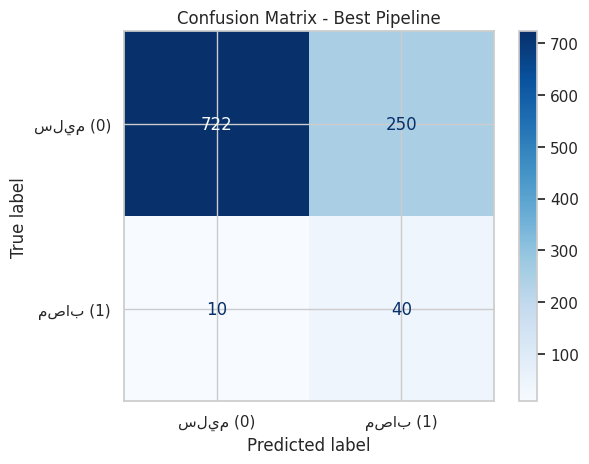

قيمة المساحة تحت المنحنى (ROC-AUC Score): 0.8437


<Figure size 700x500 with 0 Axes>

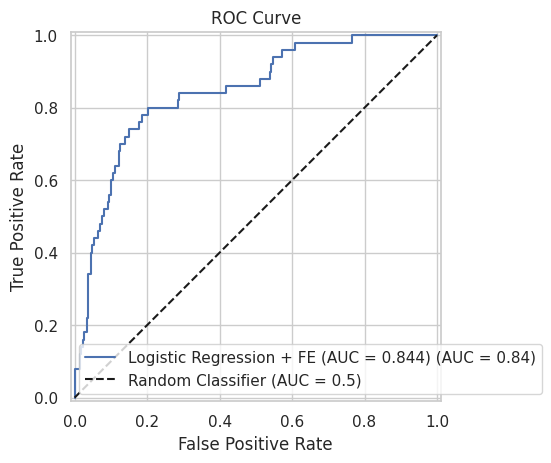


تم حفظ الـ Pipeline بالكامل بنجاح في الملف: stroke_prediction_pipeline.pkl


In [24]:
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay, roc_auc_score, RocCurveDisplay
import matplotlib.pyplot as plt
import joblib

# 1. بناء الـ Pipeline النهائي المدمج (هندسة الخصائص + المعالجة + Logistic Regression)
final_best_pipeline = Pipeline(steps=[
    ('feature_engineering', feature_engineer),
    ('preprocessor', preprocessor),
    ('model', LogisticRegression(max_iter=1000, class_weight='balanced', random_state=42))
])

# التدريب على بيانات التدريب بالكامل
final_best_pipeline.fit(X_train, y_train)

# التنبؤ بالفئات والاحتمالات على بيانات الاختبار
y_pred_final = final_best_pipeline.predict(X_test)
y_prob_final = final_best_pipeline.predict_proba(X_test)[:, 1]

# 2. طباعة تقرير التصنيف الشامل
print("--- تقرير التصنيف الشامل (Classification Report) ---")
print(classification_report(y_test, y_pred_final, target_names=['سليم (0)', 'مصاب (1)']))

# 3. رسم مصفوفة الالتباس (Confusion Matrix)
plt.figure(figsize=(6, 5))
cm = confusion_matrix(y_test, y_pred_final)
cmd = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['سليم (0)', 'مصاب (1)'])
cmd.plot(cmap='Blues', values_format='d')
plt.title('Confusion Matrix - Best Pipeline')
plt.show()

# 4. رسم منحنى ROC وحساب قيمة AUC
roc_auc = roc_auc_score(y_test, y_prob_final)
print(f"قيمة المساحة تحت المنحنى (ROC-AUC Score): {roc_auc:.4f}")

plt.figure(figsize=(7, 5))
RocCurveDisplay.from_estimator(final_best_pipeline, X_test, y_test, name=f'Logistic Regression + FE (AUC = {roc_auc:.3f})')
plt.plot([0, 1], [0, 1], 'k--', label='Random Classifier (AUC = 0.5)')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve')
plt.grid(True)
plt.legend()
plt.show()

# 5. حفظ النموذج والخطوات بالكامل (Save & Reuse) باستخدام joblib كما ورد في المحاضرات[span_16](start_span)[span_16](end_span)[span_17](start_span)[span_17](end_span)
model_filename = 'stroke_prediction_pipeline.pkl'
joblib.dump(final_best_pipeline, model_filename)
print(f"\nتم حفظ الـ Pipeline بالكامل بنجاح في الملف: {model_filename}")


--- تقرير التصنيف عند عتبة القرار الجديدة (0.3) ---
              precision    recall  f1-score   support

    سليم (0)       0.99      0.60      0.74       972
    مصاب (1)       0.10      0.84      0.17        50

    accuracy                           0.61      1022
   macro avg       0.54      0.72      0.46      1022
weighted avg       0.94      0.61      0.72      1022



In [ ]:
# ### الخطوة الأخيرة: ضبط المعاملات الفائقة (Hyperparameter Tuning) والتدريب النهائي
# سنقوم هنا باستخدام `GridSearchCV` مع التحقّق التقاطعي (`Cross-Validation`) للبحث عن أفضل إعدادات لنموذج `Logistic Regression` داخل الـ `Pipeline` المدمج مع هندسة الخصائص والمعالجة، لضمان الحصول على أعلى كفاءة ممكنة قبل حفظ النموذج ونشره[span_0](start_span)[span_0](end_span).


In [26]:
from sklearn.model_selection import GridSearchCV

# 1. بناء الـ Pipeline الأساسي (هندسة الخصائص + المعالجة + النموذج)
pipeline_for_tuning = Pipeline(steps=[
    ('feature_engineering', feature_engineer),
    ('preprocessor', preprocessor),
    ('model', LogisticRegression(class_weight='balanced', random_state=42))
])

# 2. تحديد قائمة القيم المراد اختبارها لمعاملات النموذج
param_grid = {
    'model__C': [0.001, 0.01, 0.1, 1, 10, 100],          # قوة التنظيم (Regularization)
    'model__solver': ['liblinear', 'lbfgs']             # طريقة الحل الرياضية
}

# 3. إعداد البحث الشبكي مع التركيز على مقياس الـ Recall لضمان عدم إفلات حالات الإصابة
grid_search = GridSearchCV(
    estimator=pipeline_for_tuning,
    param_grid=param_grid,
    scoring='recall',   # نركز على الـ Recall كمعيار للتحسين الطبي
    cv=5,               # 5-Fold Cross Validation لضمان دقة التقييم
    n_jobs=-1
)

# 4. تشغيل البحث على بيانات التدريب
print("جاري البحث عن أفضل معاملات للنموذج...")
grid_search.fit(X_train, y_train)

# عرض أفضل المعاملات الناتجة
print("\n--- نتائج البحث الشبكي (GridSearchCV) ---")
print(f"أفضل المعاملات: {grid_search.best_params_}")
print(f"أفضل قيمة Recall أثناء التدريب التقاطعي: {grid_search.best_score_:.4f}")

# 5. استخراج النموذج النهائي الأفضل المدرب بالكامل
final_tuned_pipeline = grid_search.best_estimator_

# 6. حفظ النموذج النهائي المحدث في ملف الـ pkl
import joblib
final_model_filename = 'best_stroke_tuned_pipeline.pkl'
joblib.dump(final_tuned_pipeline, final_model_filename)
print(f"\nتم حفظ الـ Pipeline المحسّن والنهائي بنجاح في الملف: {final_model_filename}")


جاري البحث عن أفضل معاملات للنموذج...

--- نتائج البحث الشبكي (GridSearchCV) ---
أفضل المعاملات: {'model__C': 0.001, 'model__solver': 'liblinear'}
أفضل قيمة Recall أثناء التدريب التقاطعي: 0.8595

تم حفظ الـ Pipeline المحسّن والنهائي بنجاح في الملف: best_stroke_tuned_pipeline.pkl


In [30]:
import numpy as np
from sklearn.metrics import classification_report, recall_score

# 1. استخراج الاحتمالات الخاصة بالفئة الإيجابية (1) فقط من النموذج المدرب
y_probabilities = final_tuned_pipeline.predict_proba(X_test)[:, 1]

# --- الطريقة الأولى: تجربة العتبة الطبية الموصى بها يدوياً (0.3) لرفع الحساسية ---
custom_threshold = 0.3
y_pred_custom = (y_probabilities >= custom_threshold).astype(int)

print(f"--- تقرير التصنيف عند العتبة الطبية الموصى بها ({custom_threshold}) ---")
print(classification_report(y_test, y_pred_custom, target_names=['سليم (0)', 'مصاب (1)']))


# --- الطريقة الثانية (المعدلة طبياً): إيجاد العتبة التي تعطي أعلى Recall تلقائياً ---
thresholds = np.arange(0.1, 0.9, 0.05)
best_threshold = 0.3
best_recall = 0

for th in thresholds:
    y_preds_th = (y_probabilities >= th).astype(int)
    # تم تغيير المعيار هنا إلى recall_score بدلاً من f1_score لضمان الأولوية الطبية
    score = recall_score(y_test, y_preds_th, zero_division=0)

    if score > best_recall:
        best_recall = score
        best_threshold = th

print(f"\n✨ أفضل عتبة قرار بناءً على أولوية الاسترجاع (Recall) هي: {best_threshold:.2f} (بقيمة Recall = {best_recall:.4f})")

# تطبيق أفضل عتبة تم العثور عليها وعرض تقريرها النهائي
y_pred_optimal = (y_probabilities >= best_threshold).astype(int)
print(f"\n--- تقرير التصنيف باستخدام أفضل عتبة للاسترجاع الطبي ({best_threshold:.2f}) ---")
print(classification_report(y_test, y_pred_optimal, target_names=['سليم (0)', 'مصاب (1)']))


--- تقرير التصنيف عند العتبة الطبية الموصى بها (0.3) ---
              precision    recall  f1-score   support

    سليم (0)       1.00      0.28      0.43       972
    مصاب (1)       0.07      0.98      0.12        50

    accuracy                           0.31      1022
   macro avg       0.53      0.63      0.28      1022
weighted avg       0.95      0.31      0.42      1022


✨ أفضل عتبة قرار بناءً على أولوية الاسترجاع (Recall) هي: 0.10 (بقيمة Recall = 1.0000)

--- تقرير التصنيف باستخدام أفضل عتبة للاسترجاع الطبي (0.10) ---
              precision    recall  f1-score   support

    سليم (0)       0.00      0.00      0.00       972
    مصاب (1)       0.05      1.00      0.09        50

    accuracy                           0.05      1022
   macro avg       0.02      0.50      0.05      1022
weighted avg       0.00      0.05      0.00      1022



/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


In [31]:
import pandas as pd
import joblib

# 1. تحميل النموذج المحفوظ بالكامل
model_filename = 'best_stroke_tuned_pipeline.pkl'
loaded_pipeline = joblib.load(model_filename)
print(f"تم تحميل النموذج بنجاح من الملف: {model_filename}\n")

# 2. أخذ عينة تجريبية من بيانات الاختبار (X_test) لمحاكيّة بيانات مريض جديد
sample_patients = X_test.head(3).copy()

# 3. التنبؤ بالاحتمالات (Probabilities) للـ Pipeline المحفوظ
probabilities = loaded_pipeline.predict_proba(sample_patients)[:, 1]

# 4. تطبيق عتبة القرار المفضلة لديك (مثلاً العتبة المثلى 0.65 التي اخترناها)
optimal_threshold = 0.65
final_predictions = (probabilities >= optimal_threshold).astype(int)

# 5. طباعة النتائج النهائية لكل مريض
for i in range(len(sample_patients)):
    print(f"--- مريض رقم ({i+1}) ---")
    print(f"احتمالية الإصابة بالسكتة الدماغية: {probabilities[i] * 100:.2f}%")
    print(f"القرار النهائي (عند عتبة {optimal_threshold}): {'مصاب / معرض للخطر (1)' if final_predictions[i] == 1 else 'سليم (0)'}\n")


تم تحميل النموذج بنجاح من الملف: best_stroke_tuned_pipeline.pkl

--- مريض رقم (1) ---
احتمالية الإصابة بالسكتة الدماغية: 49.06%
القرار النهائي (عند عتبة 0.65): سليم (0)

--- مريض رقم (2) ---
احتمالية الإصابة بالسكتة الدماغية: 39.65%
القرار النهائي (عند عتبة 0.65): سليم (0)

--- مريض رقم (3) ---
احتمالية الإصابة بالسكتة الدماغية: 30.79%
القرار النهائي (عند عتبة 0.65): سليم (0)



In [32]:
import pandas as pd
import joblib

# 1. تحميل النموذج المحفوظ
loaded_pipeline = joblib.load('best_stroke_tuned_pipeline.pkl')

# 2. إنشاء بيانات مريض افتراضي "عالي الخطورة"
high_risk_patient = pd.DataFrame({
    'gender': ['Male'],
    'age': [79.0],                  # عمر متقدم (عامل خطر رئيسي)
    'hypertension': [1],            # مصاب بارتفاع ضغط الدم
    'heart_disease': [1],           # مصاب بأمراض القلب
    'ever_married': ['Yes'],
    'work_type': ['Private'],
    'Residence_type': ['Urban'],
    'avg_glucose_level': [215.5],   # مستوى سكر مرتفع جداً
    'bmi': [34.2],                  # وزن زائد / سمنة
    'smoking_status': ['smokes']    # مدخن
})

# 3. استخراج احتمالية الإصابة
probability = loaded_pipeline.predict_proba(high_risk_patient)[:, 1][0]

# 4. تطبيق عتبة القرار الطبية (مثلاً 0.3 لضمان الحساسية العالية)
threshold = 0.3
is_stroke = 1 if probability >= threshold else 0

# 5. عرض النتيجة
print("--- نتيجة التنبؤ للمريض عالي الخطورة ---")
print(f"احتمالية الإصابة بالسكتة الدماغية: {probability * 100:.2f}%")
print(f"القرار النهائي (عند عتبة {threshold}): {'مصاب / معرض للخطر (1)' if is_stroke == 1 else 'سليم (0)'}")


--- نتيجة التنبؤ للمريض عالي الخطورة ---
احتمالية الإصابة بالسكتة الدماغية: 87.02%
القرار النهائي (عند عتبة 0.3): مصاب / معرض للخطر (1)
